# 04 · Phân tích Việt Nam

**Đức** · Chạy sau notebook 03. Dùng nhãn panel, không xem số nhãn là thứ hạng kinh tế.

## 1. Giới thiệu mục tiêu phân tích

Xem vị trí Việt Nam qua các năm, so sánh Đông Nam Á và thể hiện phân cụm trên bản đồ.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon, Patch
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd().resolve()
while not (ROOT / "du_lieu").is_dir():
    if ROOT == ROOT.parent:
        raise FileNotFoundError("Hãy mở notebook trong repo DBSCAN.")
    ROOT = ROOT.parent
OUT = ROOT / "ket_qua_chung/viet_nam"
FIG = ROOT / "Duc/bieu_do"
OUT.mkdir(parents=True, exist_ok=True)
KEYS = ["country", "year"]
plt.rcParams.update({"figure.figsize": (11, 4), "figure.dpi": 110})

## 2. Đọc kết quả phân cụm DBSCAN

In [2]:
clean = pd.read_csv(ROOT / "du_lieu/du_lieu_sach/wdi_clean.csv")
scaled = pd.read_csv(ROOT / "du_lieu/du_lieu_chuan_hoa/wdi_scaled.csv")
labels = pd.read_csv(ROOT / "ket_qua_chung/dbscan/dbscan_labels.csv")
params = json.loads((ROOT / "ket_qua_chung/dbscan/tham_so_da_chon.json").read_text())
profile = pd.read_csv(ROOT / "ket_qua_chung/ho_so_cum/ho_so_cum_dbscan_dang_dai.csv")
features = params["feature_columns"]
assert params["fit_scope"] == "global_panel"
assert not labels.duplicated(KEYS).any()
assert clean[KEYS].equals(labels[KEYS]) and clean[KEYS].equals(scaled[KEYS])
assert {"cluster", "feature", "median"}.issubset(profile.columns)
data = clean.merge(labels, on=KEYS, validate="one_to_one")
latest_year = int(data.year.max())
clusters = sorted(data.loc[data.cluster >= 0, "cluster"].unique())
colors = {int(k): plt.get_cmap("tab10")(i % 10) for i, k in enumerate(clusters)}
colors[-1] = "#555555"
print(f"Dùng nhãn panel: {len(data)} quốc gia–năm, {len(clusters)} cụm.")

Dùng nhãn panel: 2315 quốc gia–năm, 4 cụm.


## 3. Phân tích vị trí của Việt Nam qua các năm

Láng giềng gần trong không gian đặc trưng không nhất thiết thuộc cùng cụm.

,year,cluster,point_type
2222,2010,-1,noise
2223,2011,-1,noise
2224,2012,-1,noise
2225,2013,-1,noise
2226,2014,-1,noise
2227,2015,-1,noise
2228,2016,-1,noise
2229,2017,-1,noise
2230,2018,-1,noise
2231,2019,-1,noise


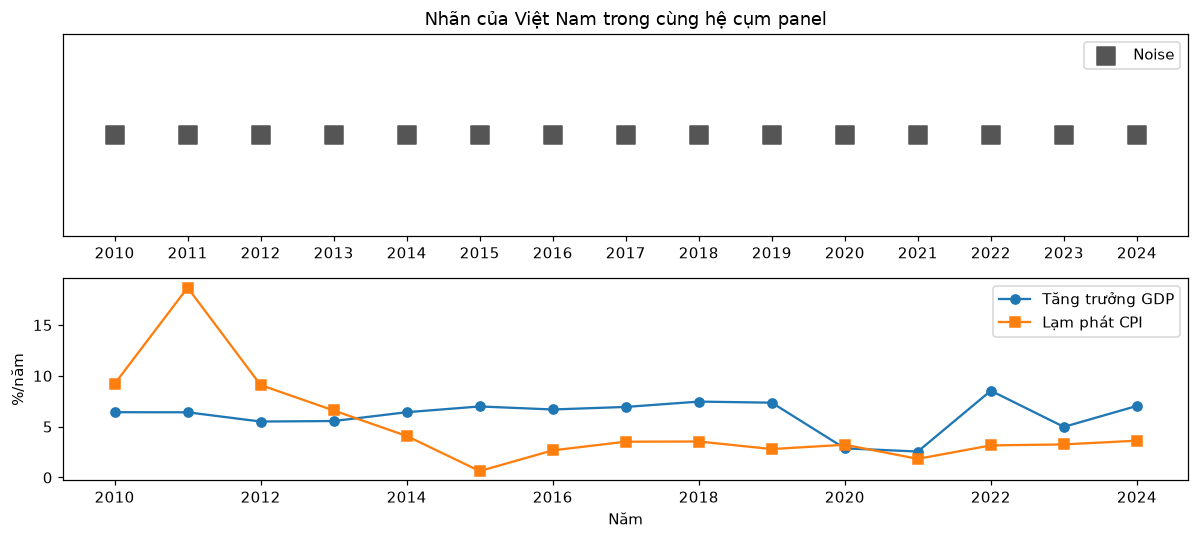

In [3]:
vietnam = data[data.country == "VNM"].sort_values("year")
assert len(vietnam) == 15 and not vietnam[features].isna().any().any()
vietnam.to_csv(OUT / "viet_nam_qua_cac_nam.csv", index=False)
display(vietnam[["year", "cluster", "point_type"]])
fig, axes = plt.subplots(2, 1, figsize=(11, 5))
for cluster, group in vietnam.groupby("cluster"):
    axes[0].scatter(group.year, np.zeros(len(group)), color=colors[cluster], s=140, marker="s",
                    label="Noise" if cluster == -1 else f"Cụm {cluster}")
axes[0].set(xticks=vietnam.year, yticks=[], title="Nhãn của Việt Nam trong cùng hệ cụm panel")
axes[0].legend()
axes[1].plot(vietnam.year, vietnam[features[1]], marker="o", label="Tăng trưởng GDP")
axes[1].plot(vietnam.year, vietnam[features[2]], marker="s", label="Lạm phát CPI")
axes[1].set(xlabel="Năm", ylabel="%/năm")
axes[1].legend(); fig.tight_layout()
fig.savefig(FIG / "07_viet_nam_qua_cac_nam.png"); plt.show()

In [4]:
latest_scaled = scaled[scaled.year == latest_year].copy()
vietnam_point = latest_scaled.loc[latest_scaled.country == "VNM", features].iloc[0].to_numpy(dtype=float)
latest_scaled["distance_to_vietnam"] = np.linalg.norm(
    latest_scaled[features].to_numpy() - vietnam_point, axis=1)
nearest = latest_scaled[latest_scaled.country != "VNM"].nsmallest(5, "distance_to_vietnam")
nearest = nearest.merge(labels, on=KEYS, validate="one_to_one")
nearest.to_csv(OUT / "quoc_gia_gan_viet_nam.csv", index=False)
display(nearest[["country", "country_name", "year", "cluster", "distance_to_vietnam"]])

,country,country_name,year,cluster,distance_to_vietnam
0,KHM,Cambodia,2024,-1,1.547407
1,GIN,Guinea,2024,-1,1.863813
2,NIC,Nicaragua,2024,0,1.917083
3,MYS,Malaysia,2024,-1,1.965598
4,MNG,Mongolia,2024,-1,1.988944


## 4. So sánh Việt Nam với các quốc gia Đông Nam Á

Ô thiếu trên heatmap là không có quan sát sau tiền xử lý, khác với nhãn noise. Giá trị chuẩn hóa cao không có nghĩa là tốt hơn.

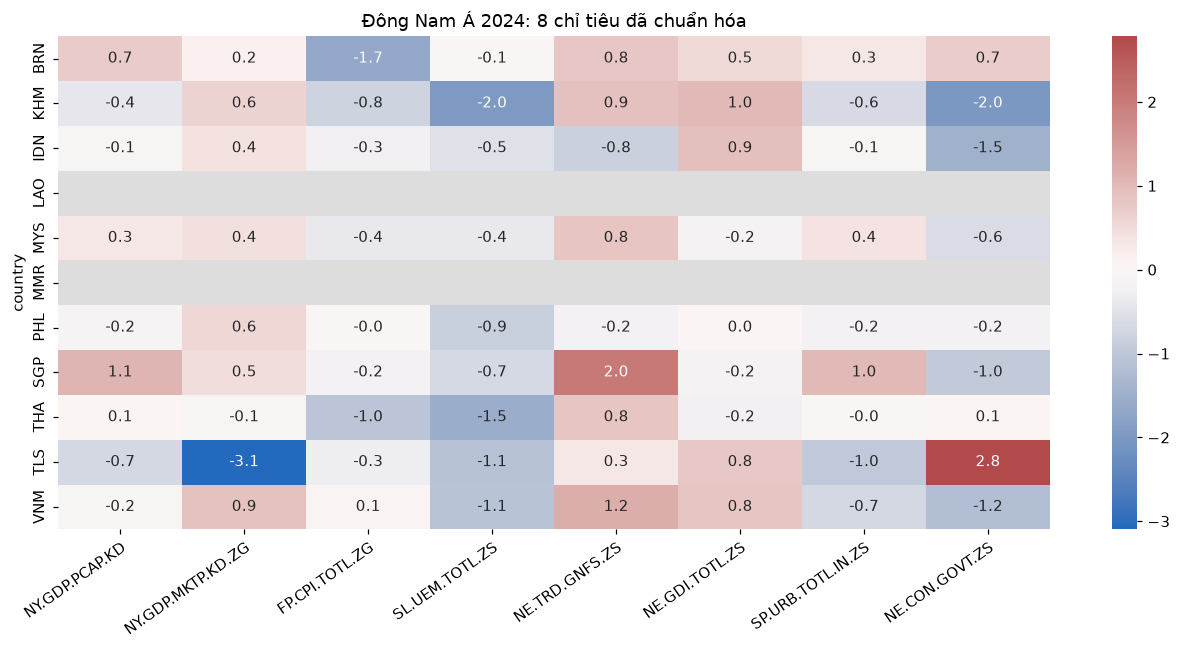

,0
country,
BRN,15
KHM,15
IDN,15
LAO,7
MYS,15
MMR,0
PHL,15
SGP,15
THA,15


In [5]:
asean = ["BRN", "KHM", "IDN", "LAO", "MYS", "MMR", "PHL", "SGP", "THA", "TLS", "VNM"]
coverage = data[data.country.isin(asean)].groupby("country").size().reindex(asean, fill_value=0)
coverage.rename("years_available").to_csv(OUT / "do_phu_dong_nam_a.csv")
regional = data[(data.year == latest_year) & data.country.isin(asean)]
regional.to_csv(OUT / "dong_nam_a_nam_moi_nhat.csv", index=False)
heatmap = latest_scaled.set_index("country")[features].reindex(asean)
fig, ax = plt.subplots(figsize=(12, 6))
ax.set_facecolor("#dddddd")
sns.heatmap(heatmap, cmap="vlag", center=0, annot=True, fmt=".1f", ax=ax)
ax.set_title(f"Đông Nam Á {latest_year}: 8 chỉ tiêu đã chuẩn hóa")
ax.set_xticklabels(features, rotation=35, ha="right", rotation_mode="anchor")
fig.tight_layout(); fig.savefig(FIG / "08_so_sanh_dong_nam_a.png"); plt.show()
display(coverage.to_frame())

## 5. Trực quan hóa bản đồ phân cụm quốc gia

Bản đồ Natural Earth 1:110m lưu sẵn trong repo. Nước nhỏ có thể thiếu hình học; danh sách được xuất riêng. Xám đậm là noise, xám nhạt là không có dữ liệu.

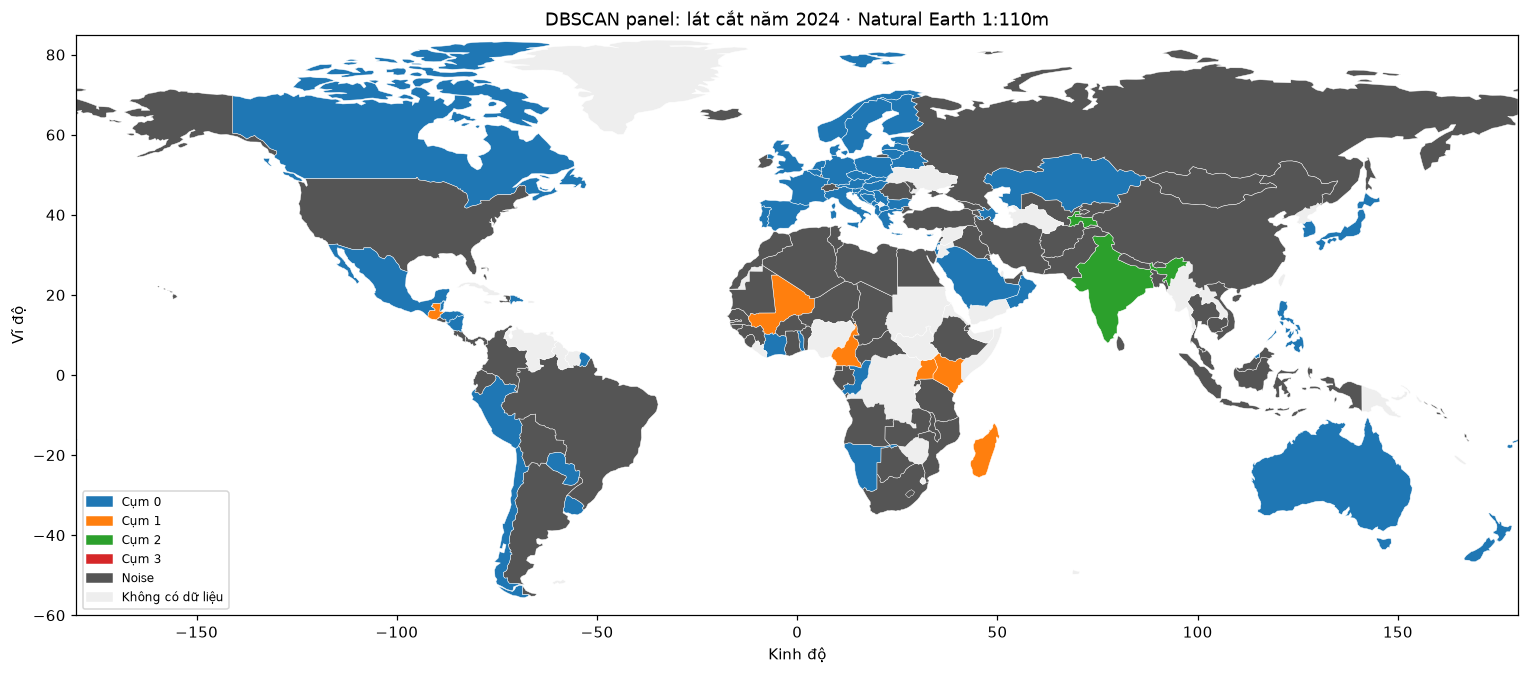

139/151 quốc gia có hình học trong bản đồ.


In [6]:
world = json.loads((ROOT / "du_lieu/ban_do/world_110m.geojson").read_text())
year_labels = data[data.year == latest_year].set_index("country").cluster.to_dict()
map_codes = set()
fig, ax = plt.subplots(figsize=(14, 6))
for feature in world["features"]:
    country = feature["properties"]["ADM0_A3"]
    map_codes.add(country)
    color = colors[year_labels[country]] if country in year_labels else "#eeeeee"
    geometry = feature["geometry"]
    polygons = geometry["coordinates"]
    if geometry["type"] == "Polygon":
        polygons = [polygons]
    for polygon in polygons:
        ax.add_patch(Polygon(polygon[0], facecolor=color, edgecolor="white", linewidth=0.3))
legend = [Patch(color=colors[k], label=f"Cụm {k}") for k in clusters]
legend += [Patch(color=colors[-1], label="Noise"), Patch(color="#eeeeee", label="Không có dữ liệu")]
ax.legend(handles=legend, loc="lower left", fontsize=8)
ax.set(xlim=(-180, 180), ylim=(-60, 85), xlabel="Kinh độ", ylabel="Vĩ độ",
       title=f"DBSCAN panel: lát cắt năm {latest_year} · Natural Earth 1:110m")
ax.set_aspect("equal"); fig.tight_layout()
fig.savefig(FIG / "09_ban_do_phan_cum.png"); plt.show()
unmapped = data[(data.year == latest_year) & ~data.country.isin(map_codes)]
unmapped[KEYS + ["country_name"]].to_csv(OUT / "khong_hien_thi_ban_do.csv", index=False)
print(f"{len(year_labels) - len(unmapped)}/{len(year_labels)} quốc gia có hình học trong bản đồ.")

## 6. Nhận xét và kết luận

Nhãn mô tả vị trí theo dữ liệu và tham số, không kết luận chính sách hoặc nguyên nhân. Với noise cao, cần đọc cả hồ sơ cụm và kiểm tra độ nhạy.

In [7]:
print(f"Việt Nam có {len(vietnam)} năm; {(vietnam.cluster == -1).sum()} năm mang nhãn noise.")
print(f"Năm so sánh: {latest_year}; Đông Nam Á có {len(regional)}/{len(asean)} nước đủ dữ liệu.")
print(f"Noise toàn panel: {params['summary']['noise_ratio']:.1%}; "
      f"đạt mục tiêu độ phủ: {params['quality_target_met']}.")
REPORT = ROOT / "ket_qua_chung/bieu_do_bao_cao"
REPORT.mkdir(parents=True, exist_ok=True)
for name in ["07_viet_nam_qua_cac_nam.png", "08_so_sanh_dong_nam_a.png", "09_ban_do_phan_cum.png"]:
    (REPORT / ("duc_" + name)).write_bytes((FIG / name).read_bytes())
assert len(pd.read_csv(OUT / "viet_nam_qua_cac_nam.csv")) == len(vietnam)
print("Đã xuất kết quả Việt Nam, Đông Nam Á và bản đồ.")

Việt Nam có 15 năm; 15 năm mang nhãn noise.
Năm so sánh: 2024; Đông Nam Á có 9/11 nước đủ dữ liệu.
Noise toàn panel: 67.2%; đạt mục tiêu độ phủ: False.
Đã xuất kết quả Việt Nam, Đông Nam Á và bản đồ.
